## Транспортные задачи

In [1]:

!pip -q install networkx pyomo highspy pandas
import networkx as nx
import pandas as pd
import pyomo.environ as pyo

from itertools import combinations, permutations
from collections import defaultdict

# Создаём решатель HiGHS.
# appsi_highs — интерфейс Pyomo к решателю HiGHS.
solver = pyo.SolverFactory("appsi_highs")

# Проверяем, что решатель доступен.
print("HiGHS доступен:", solver.available())

def solve_model(model):
    """Решает модель Pyomo и возвращает результат решения."""
    result = solver.solve(model)
    print("Статус решения:", result.solver.termination_condition)
    return result

def print_selected_arcs(model, arc_set, variable):
    """Печатает дуги, для которых значение бинарной переменной равно 1."""
    for i, j in arc_set:
        if pyo.value(variable[i, j]) > 0.5:
            print(f"{i} -> {j}")

HiGHS доступен: True


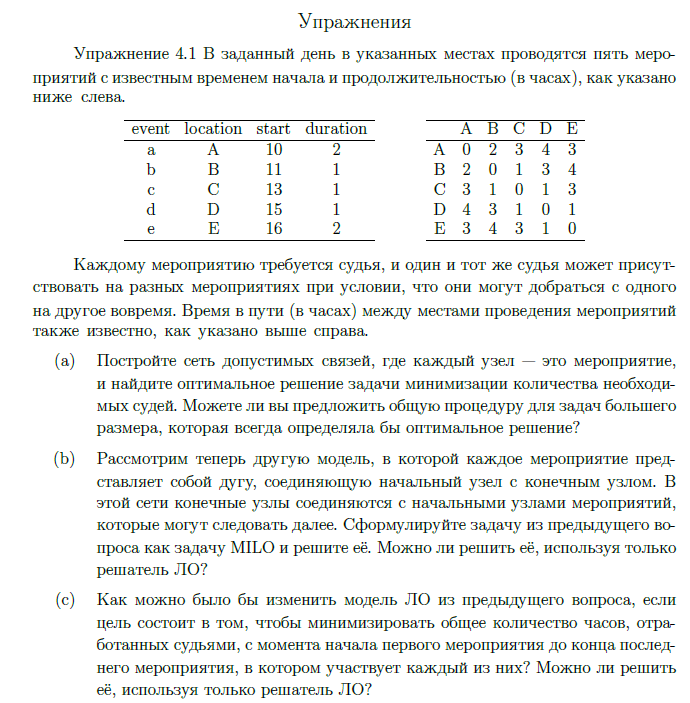

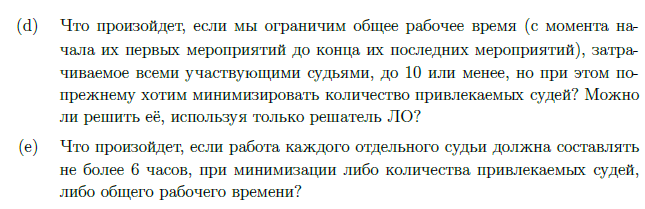

In [2]:
# Пункт (а). Построить сеть допустимых связей и минимизировать число судей.
# Данные мероприятий: место, время начала, продолжительность.
events = {
    "a": {"place": "A", "start": 10, "duration": 2},
    "b": {"place": "B", "start": 11, "duration": 1},
    "c": {"place": "C", "start": 13, "duration": 1},
    "d": {"place": "D", "start": 15, "duration": 1},
    "e": {"place": "E", "start": 16, "duration": 2},
}

# Время поездки между всеми местами из таблицы задания.
travel = {
    "A": {"A": 0, "B": 2, "C": 3, "D": 4, "E": 3},
    "B": {"A": 2, "B": 0, "C": 1, "D": 3, "E": 4},
    "C": {"A": 3, "B": 1, "C": 0, "D": 1, "E": 3},
    "D": {"A": 4, "B": 3, "C": 1, "D": 0, "E": 1},
    "E": {"A": 3, "B": 4, "C": 3, "D": 1, "E": 0},
}

# Строим ориентированный граф.
# Дуга i -> j означает, что после мероприятия i можно успеть на мероприятие j.
G_events = nx.DiGraph()
G_events.add_nodes_from(events)

compatible_arcs = []
for i, data_i in events.items():
    for j, data_j in events.items():
        if i == j:
            continue

        place_i = data_i["place"]
        place_j = data_j["place"]

        # Время, когда первое мероприятие закончилось.
        finish_i = data_i["start"] + data_i["duration"]

        # Проверяем, хватает ли времени на дорогу до второго мероприятия.
        arrival_time = finish_i + travel[place_i][place_j]

        if arrival_time <= data_j["start"]:
            G_events.add_edge(i, j)
            compatible_arcs.append((i, j))

print("Допустимые переходы между мероприятиями:")
print(compatible_arcs)

# Для минимального покрытия путями строим двудольный граф:
# слева — копии мероприятий как возможные предшественники,
# справа — копии мероприятий как возможные последователи.
B = nx.Graph()
left_nodes = [("L", e) for e in events]
right_nodes = [("R", e) for e in events]
B.add_nodes_from(left_nodes, bipartite=0)
B.add_nodes_from(right_nodes, bipartite=1)

for i, j in compatible_arcs:
    B.add_edge(("L", i), ("R", j))

# Максимальное паросочетание показывает, сколько переходов
# можно одновременно включить в расписания судей.
matching = nx.algorithms.bipartite.maximum_matching(B, top_nodes=left_nodes)

selected_transitions = []
for i, j in compatible_arcs:
    if matching.get(("L", i)) == ("R", j):
        selected_transitions.append((i, j))

# Для ациклического графа минимальное число путей,
# покрывающих все вершины, равно:
# количество вершин минус размер максимального паросочетания.
number_of_judges = len(events) - len(selected_transitions)

# Восстанавливаем расписания судей по выбранным переходам.
successor = {i: j for i, j in selected_transitions}
predecessor = {j: i for i, j in selected_transitions}

schedules = []
for event in events:
    # Начало каждого пути — мероприятие без выбранного предшественника.
    if event not in predecessor:
        path = [event]
        while path[-1] in successor:
            path.append(successor[path[-1]])
        schedules.append(path)

print("\nПереходы в оптимальном решении:", selected_transitions)
print("Минимальное количество судей:", number_of_judges)
print("Расписание:")
for k, path in enumerate(schedules, start=1):
    print(f"Судья {k}: {' -> '.join(path)}")

Допустимые переходы между мероприятиями:
[('a', 'e'), ('b', 'c'), ('b', 'd'), ('b', 'e'), ('c', 'd')]

Переходы в оптимальном решении: [('a', 'e'), ('b', 'c'), ('c', 'd')]
Минимальное количество судей: 2
Расписание:
Судья 1: a -> e
Судья 2: b -> c -> d


In [3]:
# Пункт (b). Модель, где каждое мероприятие — дуга start -> end.
# Конец мероприятия i соединяется с началом j, если переход i -> j допустим.
# Добавляем источник s и сток t: из s можно начать любое мероприятие,
# после любого мероприятия можно уйти в t.
#
# Бинарные переменные:
#   x[i,j] = 1, если после i судья идёт на j
#   start[i] = 1, если судья начинает день с мероприятия i
#   end[i] = 1, если судья заканчивает день мероприятием i
# Число судей = число стартов (= число финишей).
# Каждое мероприятие обязательно: ровно один вход и ровно один выход.

model_41b = pyo.ConcreteModel()
model_41b.EVENTS = pyo.Set(initialize=list(events))
model_41b.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)

model_41b.x = pyo.Var(model_41b.ARCS, domain=pyo.Binary)
model_41b.start = pyo.Var(model_41b.EVENTS, domain=pyo.Binary)
model_41b.end = pyo.Var(model_41b.EVENTS, domain=pyo.Binary)

# Минимизируем число судей = число начатых маршрутов.
model_41b.obj = pyo.Objective(
    expr=sum(model_41b.start[i] for i in model_41b.EVENTS),
    sense=pyo.minimize
)


def inflow_rule(m, j):
    incoming = [(i, jj) for i, jj in m.ARCS if jj == j]
    return m.start[j] + sum(m.x[i, jj] for i, jj in incoming) == 1


def outflow_rule(m, i):
    outgoing = [(ii, j) for ii, j in m.ARCS if ii == i]
    return m.end[i] + sum(m.x[ii, j] for ii, j in outgoing) == 1


model_41b.inflow = pyo.Constraint(model_41b.EVENTS, rule=inflow_rule)
model_41b.outflow = pyo.Constraint(model_41b.EVENTS, rule=outflow_rule)

solve_model(model_41b)

print("Минимальное число судей:", int(round(pyo.value(model_41b.obj))))
print("Стартовые мероприятия:",
      [i for i in events if pyo.value(model_41b.start[i]) > 0.5])
print("Выбранные переходы:")
print_selected_arcs(model_41b, compatible_arcs, model_41b.x)

# Линейная релаксация: Binary -> [0, 1].
model_41b_lp = pyo.ConcreteModel()
model_41b_lp.EVENTS = pyo.Set(initialize=list(events))
model_41b_lp.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)
model_41b_lp.x = pyo.Var(model_41b_lp.ARCS, bounds=(0, 1), domain=pyo.NonNegativeReals)
model_41b_lp.start = pyo.Var(model_41b_lp.EVENTS, bounds=(0, 1), domain=pyo.NonNegativeReals)
model_41b_lp.end = pyo.Var(model_41b_lp.EVENTS, bounds=(0, 1), domain=pyo.NonNegativeReals)

model_41b_lp.obj = pyo.Objective(
    expr=sum(model_41b_lp.start[i] for i in model_41b_lp.EVENTS),
    sense=pyo.minimize
)
model_41b_lp.inflow = pyo.Constraint(model_41b_lp.EVENTS, rule=inflow_rule)
model_41b_lp.outflow = pyo.Constraint(model_41b_lp.EVENTS, rule=outflow_rule)

solve_model(model_41b_lp)

lp_b = pyo.value(model_41b_lp.obj)
ip_b = pyo.value(model_41b.obj)
print("Значение целевой функции ЛО:", lp_b)
print("Значения переменных ЛО (переходы):")
for i, j in compatible_arcs:
    value = pyo.value(model_41b_lp.x[i, j])
    if value > 1e-6:
        print(f"x[{i},{j}] = {value:.3f}")
print("ЛО достаточна:", abs(lp_b - ip_b) < 1e-6)


Статус решения: optimal
Минимальное число судей: 2
Стартовые мероприятия: ['a', 'b']
Выбранные переходы:
a -> e
b -> c
c -> d


Статус решения: optimal
Значение целевой функции ЛО: 2.0
Значения переменных ЛО (переходы):
x[a,e] = 1.000
x[b,c] = 1.000
x[c,d] = 1.000
ЛО достаточна: True


In [4]:
# Пункт (с). Минимизировать суммарное рабочее время всех судей.
#
# Рабочее время судьи от начала первого мероприятия до конца последнего
# складывается из длительностей мероприятий и промежутков между ними.
#
# Если выбрано i -> j, добавляется промежуток:
# start(j) - (start(i) + duration(i)).
#
# Сумма длительностей всех мероприятий постоянна.
# Все промежутки неотрицательны, поэтому минимум достигается,
# когда мероприятия не объединяются в длинные маршруты.

gap = {}
for i, j in compatible_arcs:
    gap[i, j] = (
        events[j]["start"]
        - (events[i]["start"] + events[i]["duration"])
    )

model_41c = pyo.ConcreteModel()
model_41c.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)
model_41c.x = pyo.Var(model_41c.ARCS, domain=pyo.Binary)

base_duration = sum(data["duration"] for data in events.values())

model_41c.obj = pyo.Objective(
    expr=base_duration + sum(gap[i, j] * model_41c.x[i, j]
                              for i, j in model_41c.ARCS),
    sense=pyo.minimize
)

# Ограничение: у каждого мероприятия не более одного следующего.
def out_limit_41c_rule(m, i):
    outgoing = [(ii, j) for ii, j in m.ARCS if ii == i]

    # Если исходящих дуг нет, ограничение автоматически выполнено.
    if not outgoing:
        return pyo.Constraint.Feasible

    return sum(m.x[ii, j] for ii, j in outgoing) <= 1


# Ограничение: у каждого мероприятия не более одного предыдущего.
def in_limit_41c_rule(m, j):
    incoming = [(i, jj) for i, jj in m.ARCS if jj == j]

    # Если входящих дуг нет, ограничение автоматически выполнено.
    if not incoming:
        return pyo.Constraint.Feasible

    return sum(m.x[i, jj] for i, jj in incoming) <= 1


model_41c.out_limit = pyo.Constraint(
    list(events),
    rule=out_limit_41c_rule
)

model_41c.in_limit = pyo.Constraint(
    list(events),
    rule=in_limit_41c_rule
)

solve_model(model_41c)

print("Минимальное суммарное рабочее время:", pyo.value(model_41c.obj), "часов")
print("Выбранные переходы:")
print_selected_arcs(model_41c, compatible_arcs, model_41c.x)

# Проверяем, достаточно ли решателя ЛО: релаксация Binary -> [0, 1].
model_41c_lp = pyo.ConcreteModel()
model_41c_lp.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)
model_41c_lp.x = pyo.Var(model_41c_lp.ARCS, bounds=(0, 1), domain=pyo.NonNegativeReals)
model_41c_lp.obj = pyo.Objective(
    expr=base_duration + sum(gap[i, j] * model_41c_lp.x[i, j]
                             for i, j in model_41c_lp.ARCS),
    sense=pyo.minimize
)
model_41c_lp.out_limit = pyo.Constraint(list(events), rule=out_limit_41c_rule)
model_41c_lp.in_limit = pyo.Constraint(list(events), rule=in_limit_41c_rule)

solve_model(model_41c_lp)
lp_c = pyo.value(model_41c_lp.obj)
ip_c = pyo.value(model_41c.obj)
print("Значение целевой функции ЛО:", lp_c)
print("ЛО достаточна:", abs(lp_c - ip_c) < 1e-6 and all(
    abs(pyo.value(model_41c_lp.x[i, j]) - round(pyo.value(model_41c_lp.x[i, j]))) < 1e-6
    for i, j in compatible_arcs
))

Статус решения: optimal
Минимальное суммарное рабочее время: 7.0 часов
Выбранные переходы:


Статус решения: optimal
Значение целевой функции ЛО: 7.0
ЛО достаточна: True


In [5]:
# Пункт (d). Минимизировать число судей при суммарном рабочем времени не более 10 часов.
model_41d = pyo.ConcreteModel()
model_41d.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)
model_41d.EVENTS = pyo.Set(initialize=list(events))
model_41d.x = pyo.Var(model_41d.ARCS, domain=pyo.Binary)

# Число судей = число мероприятий - число выбранных переходов.
model_41d.obj = pyo.Objective(
    expr=len(events) - sum(model_41d.x[i, j] for i, j in model_41d.ARCS),
    sense=pyo.minimize
)

# Ограничение: у каждого мероприятия не более одного следующего.
def out_limit_41d_rule(m, i):
    outgoing = [(ii, j) for ii, j in m.ARCS if ii == i]

    if not outgoing:
        return pyo.Constraint.Feasible

    return sum(m.x[ii, j] for ii, j in outgoing) <= 1


# Ограничение: у каждого мероприятия не более одного предыдущего.
def in_limit_41d_rule(m, j):
    incoming = [(i, jj) for i, jj in m.ARCS if jj == j]

    if not incoming:
        return pyo.Constraint.Feasible

    return sum(m.x[i, jj] for i, jj in incoming) <= 1


model_41d.out_limit = pyo.Constraint(
    model_41d.EVENTS,
    rule=out_limit_41d_rule
)

model_41d.in_limit = pyo.Constraint(
    model_41d.EVENTS,
    rule=in_limit_41d_rule
)

# Суммарное время = длительности мероприятий + промежутки между ними.
model_41d.time_limit = pyo.Constraint(
    expr=base_duration + sum(gap[i, j] * model_41d.x[i, j]
                             for i, j in model_41d.ARCS) <= 10
)

solve_model(model_41d)

print("Минимальное число судей:", pyo.value(model_41d.obj))
print("Суммарное рабочее время:",
      base_duration + sum(gap[i, j] * pyo.value(model_41d.x[i, j])
                          for i, j in compatible_arcs))
print("Выбранные переходы:")
print_selected_arcs(model_41d, compatible_arcs, model_41d.x)

# Проверяем линейную релаксацию: достаточно ли одного решателя ЛО?
model_41d_lp = pyo.ConcreteModel()
model_41d_lp.ARCS = pyo.Set(dimen=2, initialize=compatible_arcs)
model_41d_lp.EVENTS = pyo.Set(initialize=list(events))
model_41d_lp.x = pyo.Var(model_41d_lp.ARCS, bounds=(0, 1), domain=pyo.NonNegativeReals)
model_41d_lp.obj = pyo.Objective(
    expr=len(events) - sum(model_41d_lp.x[i, j] for i, j in model_41d_lp.ARCS),
    sense=pyo.minimize
)
model_41d_lp.out_limit = pyo.Constraint(model_41d_lp.EVENTS, rule=out_limit_41d_rule)
model_41d_lp.in_limit = pyo.Constraint(model_41d_lp.EVENTS, rule=in_limit_41d_rule)
model_41d_lp.time_limit = pyo.Constraint(
    expr=base_duration + sum(gap[i, j] * model_41d_lp.x[i, j]
                             for i, j in model_41d_lp.ARCS) <= 10
)

solve_model(model_41d_lp)
lp_d = pyo.value(model_41d_lp.obj)
ip_d = pyo.value(model_41d.obj)
print("Значение целевой функции ЛО:", lp_d)
print("Значения переменных ЛО:")
for i, j in compatible_arcs:
    value = pyo.value(model_41d_lp.x[i, j])
    if value > 1e-6:
        print(f"x[{i},{j}] = {value:.3f}")
print("ЛО достаточна:", abs(lp_d - ip_d) < 1e-6)
if abs(lp_d - ip_d) >= 1e-6:
    print("Нужен ЦЛО/MILO: релаксация даёт дробный оптимум", lp_d,
          "вместо целочисленного", ip_d)

Статус решения:

 optimal
Минимальное число судей: 3.0
Суммарное рабочее время: 9.0
Выбранные переходы:
b -> c
c -> d
Статус решения: optimal
Значение целевой функции ЛО: 2.75
Значения переменных ЛО:
x[a,e] = 0.250
x[b,c] = 1.000
x[c,d] = 1.000
ЛО достаточна: False
Нужен ЦЛО/MILO: релаксация даёт дробный оптимум 2.75 вместо целочисленного 3.0


In [6]:
# Пункт (e). Ограничить рабочее время каждого судьи 6 часами.
#
# Для этого подпункта удобно перечислить все допустимые маршруты судьи.
# Затем выбираем набор маршрутов так, чтобы каждое мероприятие встретилось ровно один раз.
# Это модель покрытия множеств (set partitioning).

def all_event_paths(graph, max_span=None):
    """Возвращает все непустые простые направленные пути в графе."""
    paths = []
    for start in graph.nodes:
        stack = [(start, [start])]
        while stack:
            node, path = stack.pop()
            paths.append(path)
            for nxt in graph.successors(node):
                if nxt not in path:
                    stack.append((nxt, path + [nxt]))

    # Убираем возможные дубликаты, сохраняя порядок.
    unique = []
    seen = set()
    for path in paths:
        key = tuple(path)
        if key not in seen:
            seen.add(key)
            if max_span is None:
                unique.append(path)
            else:
                span = (events[path[-1]]["start"] + events[path[-1]]["duration"]
                        - events[path[0]]["start"])
                if span <= max_span:
                    unique.append(path)
    return unique

# Оставляем только маршруты, где рабочее время не превышает 6 часов.
valid_paths_6 = all_event_paths(G_events, max_span=6)

# Создаём модель выбора маршрутов.
model_41e = pyo.ConcreteModel()
model_41e.PATHS = pyo.Set(initialize=list(range(len(valid_paths_6))))
model_41e.EVENTS = pyo.Set(initialize=list(events))
model_41e.z = pyo.Var(model_41e.PATHS, domain=pyo.Binary)

# Вариант 1: минимизируем количество судей.
model_41e.obj = pyo.Objective(
    expr=sum(model_41e.z[p] for p in model_41e.PATHS),
    sense=pyo.minimize
)

# Каждое мероприятие должно входить ровно в один выбранный маршрут.
def cover_event_rule(m, event):
    return sum(m.z[p] for p, path in enumerate(valid_paths_6)
               if event in path) == 1

model_41e.cover = pyo.Constraint(model_41e.EVENTS, rule=cover_event_rule)

solve_model(model_41e)

chosen_paths = [valid_paths_6[p] for p in model_41e.PATHS
                if pyo.value(model_41e.z[p]) > 0.5]

print("Минимальное количество судей:", len(chosen_paths))
print("Маршруты:")
for k, path in enumerate(chosen_paths, 1):
    span = (events[path[-1]]["start"] + events[path[-1]]["duration"]
            - events[path[0]]["start"])
    print(f"Судья {k}: {' -> '.join(path)}, рабочее время = {span} ч")

# Вариант 2: минимизируем суммарное рабочее время.
model_41e_time = pyo.ConcreteModel()
model_41e_time.PATHS = pyo.Set(initialize=list(range(len(valid_paths_6))))
model_41e_time.EVENTS = pyo.Set(initialize=list(events))
model_41e_time.z = pyo.Var(model_41e_time.PATHS, domain=pyo.Binary)

path_span = {
    p: events[path[-1]]["start"] + events[path[-1]]["duration"]
       - events[path[0]]["start"]
    for p, path in enumerate(valid_paths_6)
}

model_41e_time.obj = pyo.Objective(
    expr=sum(path_span[p] * model_41e_time.z[p] for p in model_41e_time.PATHS),
    sense=pyo.minimize
)
model_41e_time.cover = pyo.Constraint(
    model_41e_time.EVENTS,
    rule=lambda m, event: sum(m.z[p] for p, path in enumerate(valid_paths_6)
                              if event in path) == 1
)

solve_model(model_41e_time)
print("Минимальное суммарное рабочее время:",
      pyo.value(model_41e_time.obj), "часов")

Статус решения: optimal
Минимальное количество судей: 3
Маршруты:
Судья 1: a, рабочее время = 2 ч
Судья 2: b -> c -> d, рабочее время = 5 ч
Судья 3: e, рабочее время = 2 ч
Статус решения: optimal
Минимальное суммарное рабочее время: 7.0 часов


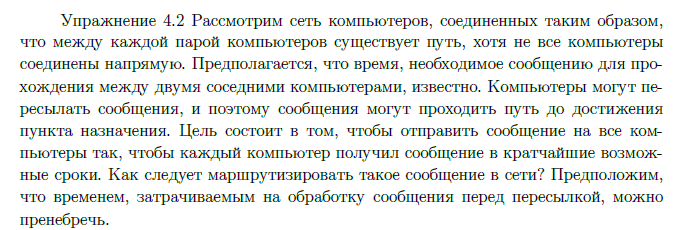

In [7]:
# Ответ: сообщение нужно маршрутизировать по дереву кратчайших путей (SPT)
# от исходного компьютера. Тогда каждый узел v получает сообщение за время
# dist(s, v) — минимально возможное при нулевом времени обработки.
# Алгоритм: Дейкстра (или Беллман–Форд при отрицательных весах).
#
# Ниже — демонстрация на учебном примере (в условии числовой сети нет).

G_comp = nx.Graph()

computer_edges = [
    ("A", "B", 4),
    ("A", "C", 2),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 8),
    ("C", "E", 10),
    ("D", "E", 2),
    ("D", "F", 6),
    ("E", "F", 3),
]
G_comp.add_weighted_edges_from(computer_edges)

source = "A"

distances, paths = nx.single_source_dijkstra(G_comp, source, weight="weight")

print("Минимальное время получения сообщения каждым компьютером:")
for node in sorted(G_comp.nodes):
    print(f"{node}: {distances[node]}")

broadcast_tree = nx.DiGraph()
for node, path in paths.items():
    if len(path) > 1:
        broadcast_tree.add_edge(
            path[-2], path[-1],
            weight=G_comp[path[-2]][path[-1]]["weight"]
        )

print("\nРёбра дерева рассылки (SPT):")
for u, v, data in broadcast_tree.edges(data=True):
    print(f"{u} -> {v}, время передачи = {data['weight']}")

print("\nПуть сообщения от исходного компьютера:")
for node, path in paths.items():
    print(f"До {node}: {' -> '.join(path)}")


Минимальное время получения сообщения каждым компьютером:
A: 0
B: 3
C: 2
D: 8
E: 10
F: 13

Рёбра дерева рассылки (SPT):
C -> B, время передачи = 1
B -> D, время передачи = 5
A -> C, время передачи = 2
D -> E, время передачи = 2
E -> F, время передачи = 3

Путь сообщения от исходного компьютера:
До A: A
До B: A -> C -> B
До C: A -> C
До D: A -> C -> B -> D
До E: A -> C -> B -> D -> E
До F: A -> C -> B -> D -> E -> F


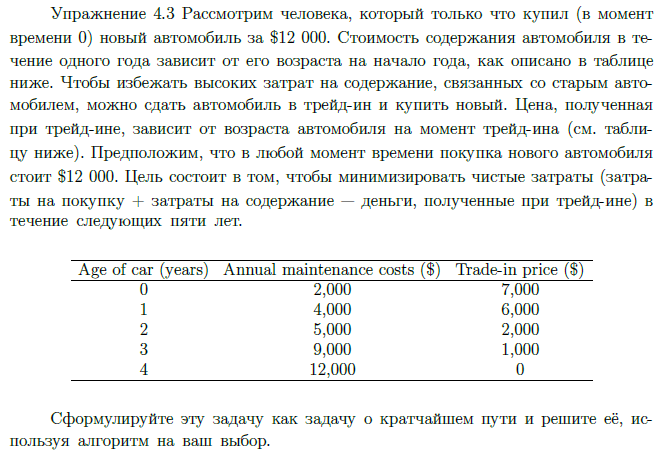

In [8]:
maintenance = {0: 2000, 1: 4000, 2: 5000, 3: 9000, 4: 12000}
trade_in = {0: 7000, 1: 6000, 2: 2000, 3: 1000, 4: 0}
purchase_price = 12000
planning_horizon = 5

G_car = nx.DiGraph()
G_car.add_nodes_from(range(planning_horizon + 1))

# Дуга i -> j: купить машину в году i и использовать её до года j.
for i in range(planning_horizon):
    for j in range(i + 1, planning_horizon + 1):
        age_at_replacement = j - i

        # Обслуживание за каждый год использования.
        service_cost = sum(maintenance[age]
                           for age in range(age_at_replacement))

        # Чистые затраты = покупка + обслуживание - трейд-ин.
        # В конце горизонта тоже учитываем остаточную стоимость
        # (для возраста 5 в таблице нет цены — берём 0).
        salvage = trade_in.get(age_at_replacement, 0)
        net_purchase_and_trade = purchase_price - salvage

        total_cost = service_cost + net_purchase_and_trade

        G_car.add_edge(i, j, weight=total_cost)

# Находим кратчайший путь.
best_path = nx.shortest_path(G_car, source=0, target=planning_horizon,
                             weight="weight")
best_cost = nx.shortest_path_length(G_car, source=0, target=planning_horizon,
                                    weight="weight")

print("Оптимальный путь по годам:", best_path)
print("Минимальные суммарные затраты:", best_cost, "долларов")

print("\nРешение:")
for year in best_path[1:-1]:
    print(f"Заменить автомобиль в начале {year}-го года")

Оптимальный путь по годам: [0, 2, 5]
Минимальные суммарные затраты: 38000 долларов

Решение:
Заменить автомобиль в начале 2-го года


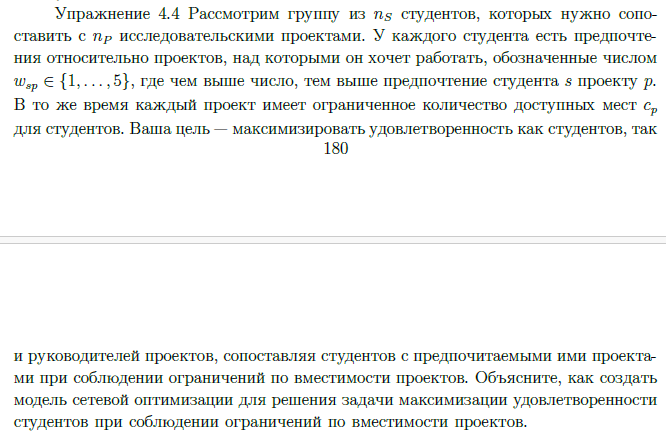

In [9]:
students = ["S1", "S2", "S3", "S4"]
projects = ["P1", "P2", "P3"]

# Оценка предпочтения студента: от 1 до 5.
preference = {
    ("S1", "P1"): 5, ("S1", "P2"): 3, ("S1", "P3"): 2,
    ("S2", "P1"): 4, ("S2", "P2"): 5, ("S2", "P3"): 1,
    ("S3", "P1"): 2, ("S3", "P2"): 4, ("S3", "P3"): 5,
    ("S4", "P1"): 3, ("S4", "P2"): 2, ("S4", "P3"): 5,
}

# Количество мест в каждом проекте.
capacity = {"P1": 1, "P2": 1, "P3": 2}

# Строим сеть для min-cost flow.
G_assign = nx.DiGraph()
source, sink = "SOURCE", "SINK"

G_assign.add_node(source, demand=-len(students))
G_assign.add_node(sink, demand=len(students))

for s in students:
    G_assign.add_edge(source, s, capacity=1, weight=0)

for p in projects:
    G_assign.add_edge(p, sink, capacity=capacity[p], weight=0)

for s in students:
    for p in projects:
        # Минус предпочтение: алгоритм минимизирует стоимость,
        # а нам нужно максимизировать предпочтение.
        G_assign.add_edge(s, p, capacity=1, weight=-preference[s, p])

# Решаем задачу потока минимальной стоимости.
flow = nx.min_cost_flow(G_assign)

total_preference = 0
print("Назначения студентов:")
for s in students:
    for p in projects:
        if flow[s].get(p, 0) > 0:
            score = preference[s, p]
            total_preference += score
            print(f"{s} -> {p}, оценка предпочтения = {score}")

print("Сумма оценок предпочтений:", total_preference)

Назначения студентов:
S1 -> P1, оценка предпочтения = 5
S2 -> P2, оценка предпочтения = 5
S3 -> P3, оценка предпочтения = 5
S4 -> P3, оценка предпочтения = 5
Сумма оценок предпочтений: 20


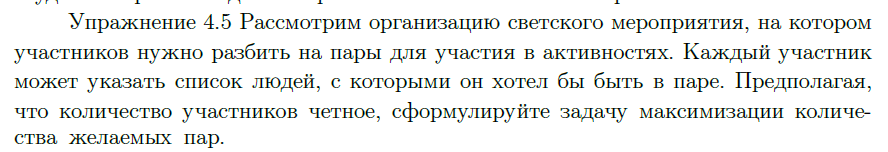

In [10]:
participants = ["A", "B", "C", "D", "E", "F"]

# Список людей, с которыми каждый участник хотел бы быть в паре.
wishes = {
    "A": ["B", "C"],
    "B": ["A"],
    "C": ["D"],
    "D": ["C", "E"],
    "E": ["F"],
    "F": ["E", "A"],
}

G_pairs = nx.Graph()
G_pairs.add_nodes_from(participants)

# Добавляем все возможные пары.
# Вес 1 означает, что пара желаемая хотя бы для одного участника.
for a, b in combinations(participants, 2):
    desired = (b in wishes[a]) or (a in wishes[b])
    G_pairs.add_edge(a, b, weight=1 if desired else 0)

# Находим паросочетание максимального веса.
matching = nx.max_weight_matching(
    G_pairs,
    maxcardinality=True,
    weight="weight"
)

desired_pair_count = 0
print("Получившиеся пары:")
for a, b in matching:
    is_desired = G_pairs[a][b]["weight"] == 1
    desired_pair_count += int(is_desired)
    print(f"{a} — {b}; желаемая пара: {is_desired}")

print("Количество желаемых пар:", desired_pair_count)

Получившиеся пары:
A — B; желаемая пара: True
E — F; желаемая пара: True
C — D; желаемая пара: True
Количество желаемых пар: 3


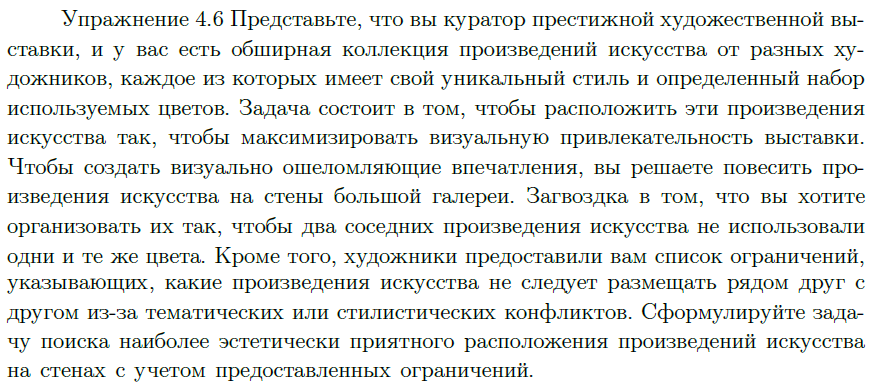

In [11]:
artworks = ["A", "B", "C", "D", "E"]

# Цвета, используемые каждым произведением.
# Наборы цветов пересекаются, чтобы цветовой запрет реально отсекал соседства.
colors = {
    "A": {"red", "blue"},
    "B": {"blue"},
    "C": {"green"},
    "D": {"red", "yellow"},
    "E": {"purple", "green"},
}

# Пары, которые запрещено размещать рядом по тематическим причинам.
conflicts = {frozenset(("A", "D")), frozenset(("B", "E"))}

# Эстетическая оценка соседства.
# В реальной задаче эти оценки задаются исходными данными.
score = {}
for i in artworks:
    for j in artworks:
        if i != j:
            score[i, j] = 1 + ((ord(i) + ord(j)) % 10)

# Оставляем только разрешённые направленные соседства.
allowed_pairs = []
for i in artworks:
    for j in artworks:
        if i == j:
            continue
        share_color = len(colors[i] & colors[j]) > 0
        conflict_pair = frozenset((i, j)) in conflicts
        if not share_color and not conflict_pair:
            allowed_pairs.append((i, j))

n = len(artworks)
positions = list(range(n))

model_46 = pyo.ConcreteModel()
model_46.I = pyo.Set(initialize=artworks)
model_46.P = pyo.Set(initialize=positions)
model_46.ALLOWED = pyo.Set(dimen=2, initialize=allowed_pairs)

# x[i,p] = 1, если произведение i стоит на позиции p.
model_46.x = pyo.Var(model_46.I, model_46.P, domain=pyo.Binary)

# y[i,j,p] = 1, если i стоит на позиции p, а j — на следующей позиции.
model_46.y = pyo.Var(
    model_46.ALLOWED,
    range(n - 1),
    domain=pyo.Binary
)

# Каждое произведение используется ровно один раз.
model_46.each_artwork_once = pyo.Constraint(
    model_46.I,
    rule=lambda m, i: sum(m.x[i, p] for p in m.P) == 1
)

# Каждая позиция занята ровно одним произведением.
model_46.each_position_once = pyo.Constraint(
    model_46.P,
    rule=lambda m, p: sum(m.x[i, p] for i in m.I) == 1
)

# Связываем переменные y с соседними позициями x.
model_46.y_left = pyo.Constraint(
    model_46.ALLOWED, range(n - 1),
    rule=lambda m, i, j, p: m.y[i, j, p] <= m.x[i, p]
)
model_46.y_right = pyo.Constraint(
    model_46.ALLOWED, range(n - 1),
    rule=lambda m, i, j, p: m.y[i, j, p] <= m.x[j, p + 1]
)
model_46.y_lower = pyo.Constraint(
    model_46.ALLOWED, range(n - 1),
    rule=lambda m, i, j, p: m.y[i, j, p] >= m.x[i, p] + m.x[j, p + 1] - 1
)

# На каждом соседнем переходе должна быть выбрана ровно одна разрешённая пара.
model_46.adjacency = pyo.Constraint(
    range(n - 1),
    rule=lambda m, p: sum(m.y[i, j, p] for i, j in m.ALLOWED) == 1
)

# Максимизируем суммарную оценку соседства.
model_46.obj = pyo.Objective(
    expr=sum(score[i, j] * model_46.y[i, j, p]
             for i, j in model_46.ALLOWED for p in range(n - 1)),
    sense=pyo.maximize
)

solve_model(model_46)

arrangement = [None] * n
for i in artworks:
    for p in positions:
        if pyo.value(model_46.x[i, p]) > 0.5:
            arrangement[p] = i

print("Оптимальный порядок произведений:")
print(" -> ".join(arrangement))
print("Суммарная эстетическая оценка:", pyo.value(model_46.obj))


Статус решения: optimal
Оптимальный порядок произведений:
B -> C -> D -> E -> A
Суммарная эстетическая оценка: 23.0


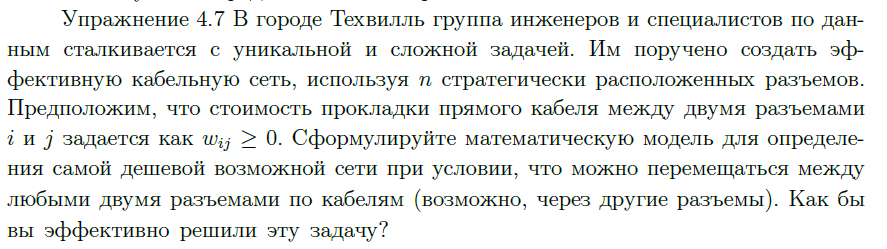

In [12]:
# Математическая модель MST:
#   min  Σ_{(i,j) ∈ E} w_ij * x_ij
#   s.t. выбранные рёбра связывают все вершины
#        (эквивалентно: |E'| = n - 1 и нет циклов,
#         или cut-constraints: для любого S ⊂ V, S ≠ ∅, V
#         Σ_{рёбра через разрез} x_e ≥ 1)
# Эффективное решение: алгоритм Краскала или Прима, O(E log V).

cable_edges = [
    ("A", "B", 4),
    ("A", "C", 3),
    ("A", "D", 7),
    ("B", "C", 2),
    ("B", "E", 5),
    ("C", "D", 4),
    ("C", "E", 6),
    ("D", "E", 1),
]

G_cable = nx.Graph()
G_cable.add_weighted_edges_from(cable_edges)

mst = nx.minimum_spanning_tree(G_cable, weight="weight")

print("Кабели, которые нужно проложить:")
for u, v, data in mst.edges(data=True):
    print(f"{u} — {v}: стоимость {data['weight']}")

total_cable_cost = sum(data["weight"] for _, _, data in mst.edges(data=True))
print("Минимальная общая стоимость:", total_cable_cost)
print("Количество компонент связности:", nx.number_connected_components(mst))


Кабели, которые нужно проложить:
A — C: стоимость 3
B — C: стоимость 2
C — D: стоимость 4
D — E: стоимость 1
Минимальная общая стоимость: 10
Количество компонент связности: 1


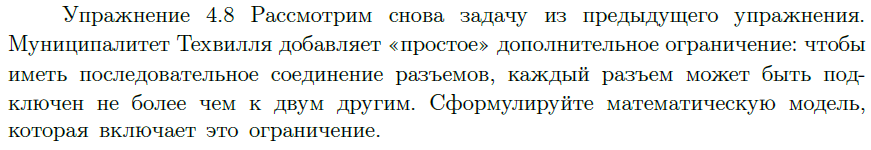

In [13]:
nodes_48 = ["A", "B", "C", "D", "E"]
edges_48 = [
    ("A", "B", 4),
    ("A", "C", 3),
    ("A", "D", 7),
    ("B", "C", 2),
    ("B", "E", 5),
    ("C", "D", 4),
    ("C", "E", 6),
    ("D", "E", 1),
]

# Нормализуем порядок концов каждого неориентированного ребра.
edges_48 = [(min(i, j), max(i, j), w) for i, j, w in edges_48]
edge_list_48 = [(i, j) for i, j, w in edges_48]
weight_48 = {(i, j): w for i, j, w in edges_48}

model_48 = pyo.ConcreteModel()
model_48.V = pyo.Set(initialize=nodes_48)
model_48.E = pyo.Set(dimen=2, initialize=edge_list_48)
model_48.x = pyo.Var(model_48.E, domain=pyo.Binary)

# Минимизируем стоимость выбранных кабелей.
model_48.obj = pyo.Objective(
    expr=sum(weight_48[i, j] * model_48.x[i, j] for i, j in model_48.E),
    sense=pyo.minimize
)

# Для дерева на n вершинах должно быть ровно n-1 ребро.
model_48.edge_count = pyo.Constraint(
    expr=sum(model_48.x[i, j] for i, j in model_48.E) == len(nodes_48) - 1
)

# Степень каждой вершины не должна превышать 2.
def degree_rule(m, v):
    return sum(m.x[i, j] for i, j in m.E if i == v or j == v) <= 2

model_48.degree_limit = pyo.Constraint(model_48.V, rule=degree_rule)

# Ограничения связности: для любого непустого собственного подмножества S
# должно быть хотя бы одно выбранное ребро, соединяющее S с остальными вершинами.
cut_sets = []
for r in range(1, len(nodes_48)):
    for subset in combinations(nodes_48, r):
        S = set(subset)
        cut_edges = [(i, j) for i, j in edge_list_48
                     if (i in S and j not in S) or (j in S and i not in S)]
        cut_sets.append((tuple(sorted(S)), cut_edges))

model_48.CUTS = pyo.Set(initialize=list(range(len(cut_sets))))
model_48.connectivity = pyo.Constraint(
    model_48.CUTS,
    rule=lambda m, k: sum(m.x[i, j] for i, j in cut_sets[k][1]) >= 1
)

solve_model(model_48)

chosen_cables = []
for i, j in edge_list_48:
    if pyo.value(model_48.x[i, j]) > 0.5:
        chosen_cables.append((i, j, weight_48[i, j]))

print("Выбранные кабели:")
for i, j, w in chosen_cables:
    print(f"{i} — {j}: стоимость {w}")

print("Общая стоимость:", pyo.value(model_48.obj))

Статус решения:

 optimal
Выбранные кабели:
A — C: стоимость 3
B — C: стоимость 2
B — E: стоимость 5
D — E: стоимость 1
Общая стоимость: 11.0


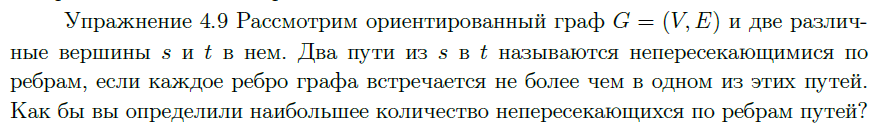

In [14]:
G_paths = nx.DiGraph()

# Ориентированные рёбра графа.
# Пропускная способность каждого ребра равна 1.
path_edges = [
    ("s", "a"), ("s", "b"),
    ("a", "c"), ("a", "d"),
    ("b", "c"), ("b", "e"),
    ("c", "t"), ("d", "t"), ("e", "t"),
]

for u, v in path_edges:
    G_paths.add_edge(u, v, capacity=1)

source, target = "s", "t"

# Находим максимальный поток.
flow_value, flow_dict = nx.maximum_flow(
    G_paths, source, target, capacity="capacity"
)

print("Максимальное количество непересекающихся по рёбрам путей:",
      int(flow_value))

# Разложим целочисленный поток на отдельные пути.
# При целых пропускных способностях алгоритм возвращает целочисленный поток.
remaining_flow = {
    u: dict(v_dict) for u, v_dict in flow_dict.items()
}

found_paths = []
for _ in range(int(flow_value)):
    # Создаём граф только из рёбер с положительным остаточным потоком.
    positive_flow_graph = nx.DiGraph()
    for u in remaining_flow:
        for v, amount in remaining_flow[u].items():
            if amount > 0:
                positive_flow_graph.add_edge(u, v)

    path = nx.shortest_path(positive_flow_graph, source, target)
    found_paths.append(path)

    # Уменьшаем поток на единицу на каждом ребре найденного пути.
    for u, v in zip(path[:-1], path[1:]):
        remaining_flow[u][v] -= 1

print("\nНайденные непересекающиеся пути:")
for path in found_paths:
    print(" -> ".join(path))

Максимальное количество непересекающихся по рёбрам путей: 2

Найденные непересекающиеся пути:
s -> a -> d -> t
s -> b -> c -> t


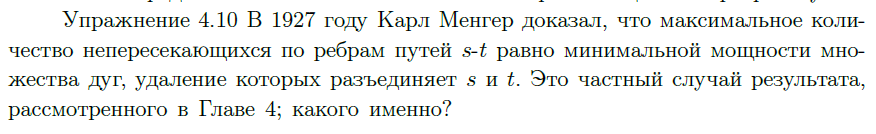

In [15]:
# Ответ: теорема Менгера (рёберная версия) — частный случай
# теоремы о максимальном потоке и минимальном разрезе,
# когда пропускная способность каждой дуги равна 1.
#
# Используем граф из упражнения 4.9.

G_paths = nx.DiGraph()

path_edges = [
    ("s", "a"), ("s", "b"),
    ("a", "c"), ("a", "d"),
    ("b", "c"), ("b", "e"),
    ("c", "t"), ("d", "t"), ("e", "t"),
]

for u, v in path_edges:
    G_paths.add_edge(u, v, capacity=1)

max_flow_value, _ = nx.maximum_flow(
    G_paths, "s", "t", capacity="capacity"
)

cut_value, (source_side, target_side) = nx.minimum_cut(
    G_paths, "s", "t", capacity="capacity"
)

print("Максимальный поток:", max_flow_value)
print("Минимальный разрез:", cut_value)
print("Вершины со стороны источника:", source_side)
print("Вершины со стороны стока:", target_side)

cut_edges = [
    (u, v)
    for u in source_side
    for v in target_side
    if G_paths.has_edge(u, v)
]

print("Рёбра минимального разреза:", cut_edges)
print("Равенство max-flow = min-cut выполнено:", max_flow_value == cut_value)
print("Вывод: это частный случай теоремы о максимальном потоке и минимальном разрезе.")


Максимальный поток: 2
Минимальный разрез: 2
Вершины со стороны источника: {'s'}
Вершины со стороны стока: {'t', 'b', 'c', 'd', 'a', 'e'}
Рёбра минимального разреза: [('s', 'b'), ('s', 'a')]
Равенство max-flow = min-cut выполнено: True
Вывод: это частный случай теоремы о максимальном потоке и минимальном разрезе.
